In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words=open("names.txt","r").read().splitlines()

In [3]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
len(words)

32033

In [5]:
stoi={s:i+1 for i,s in enumerate(sorted(set(''.join(words))))}
stoi['.']=0
itos={i:s for s,i in stoi.items()}
vocab_size=len(itos)

In [6]:
block_size=4
X,Y=[],[]
for w in words:
    
    content=[0]*block_size
    for ch in w+'.':
        ix=stoi[ch]
        X.append(content)
        Y.append(ix)
        content=content[1:]+[ix]
X=torch.tensor(X)
Y=torch.tensor(Y)

In [7]:
def datasets(words):
    block_size=4
    X,Y=[],[]
    for w in words:
        
        content=[0]*block_size
        for ch in w+'.':
            ix=stoi[ch]
            X.append(content)
            Y.append(ix)
            content=content[1:]+[ix]
    X=torch.tensor(X)
    Y=torch.tensor(Y)
    print(X.shape,Y.shape)
    return X,Y

In [8]:
import random
random.seed(42)
random.shuffle(words)
n1=int(0.8*(len(words)))
n2=int(0.9*(len(words)))
Xtr,Ytr=datasets(words[:n1])
Xdev,Ydev=datasets(words[n1:n2])
Xtest,Ytest=datasets(words[n2:])

torch.Size([182625, 4]) torch.Size([182625])
torch.Size([22655, 4]) torch.Size([22655])
torch.Size([22866, 4]) torch.Size([22866])


In [9]:
class Linear:
    def __init__(self,fan_in,fan_out,bias=True):
        self.weight=torch.randn((fan_in,fan_out),generator=g)/fan_in**0.5
        self.bias=torch.zeros(fan_out) if bias else None
    def __call__(self,x):
        self.out=x@self.weight
        if self.bias is not None:
            self.out+=self.bias
        return self.out
    def parameters(self,):
        return [self.weight]+([] if self.bias is None  else [self.bias])
class BatchNorm1d:
    def __init__(self,dim,eps=1e-5,momentun=0.1):
        self.eps=eps
        self.training=True
        self.momentun=momentun
        self.gamma=torch.ones(dim)
        self.beta=torch.zeros(dim)
        self.mean_running=torch.zeros(dim)
        self.var_running=torch.ones(dim)
    def __call__(self,x):
        if self.training:
            xmean=x.mean(0,keepdim=True)
            xvar=x.var(0,keepdim=True,unbiased=True)
        else:
            xmean=self.mean_running
            xvar=self.var_running
        xhat=(x-xmean)/torch.sqrt(xvar+self.eps)
        self.out=xhat*self.gamma+self.beta
        if self.training:
            with torch.no_grad():
                self.mean_running=(1-self.momentun)*self.mean_running+self.momentun*xmean
                self.var_running=(1-self.momentun)*self.var_running+self.momentun*xvar
        return self.out
    def parameters(self):
        return [self.gamma]+[self.beta]
class Tanh():
    def __call__(self,x):
        self.out=torch.tanh(x)
        return self.out

    def parameters(self,):
        return []
class Embeddinng (nin,nout):
    self.weight=torch.ranin((nin,nout))


In [11]:
g=torch.Generator().manual_seed(2147483647)
n_embd=10
n_hidden=100
C=torch.randn((vocab_size,n_embd),generator=g)
layers=[
    Linear(n_embd*block_size,n_hidden),BatchNorm1d(n_hidden),Tanh(),
    Linear(n_hidden,n_hidden),BatchNorm1d(n_hidden),Tanh(),
    Linear(n_hidden,n_hidden),BatchNorm1d(n_hidden),Tanh(),   
    Linear(n_hidden,n_hidden),BatchNorm1d(n_hidden),Tanh(),
    Linear(n_hidden,n_hidden),BatchNorm1d(n_hidden),Tanh(),
    Linear(n_hidden,vocab_size),BatchNorm1d(vocab_size),
]
with torch.no_grad():
    layers[-1].gamma*=0.1
    for layer in layers[:-1]:
        if isinstance(layer,Linear):
            layer.weight*=5/3
parameters=[C] +[p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad=True

48551


In [12]:
lossi=[]
ud=[]
max_steps=200000
batch_size=32
for i in range(max_steps):
    ix=torch.randint(0,Xtr.shape[0],(batch_size,))
    xb,yb=Xtr[ix],Ytr[ix]
    emd=C[xb]
    x=emd.view(emd.shape[0],-1)
    for layer in layers:
        x=layer(x)
    loss=F.cross_entropy(x,yb)
    for layer in layers:
        layer.out.retain_grad()
    for p in parameters:
        p.grad=None
    loss.backward()
    lr=0.1
    for p in parameters:
        p.data+=-lr*p.grad
    if i%10000==0:
        print(f'{i:7d}/{max_steps:7d} :{loss.item():.4f}')
    with torch.no_grad():
        ud.append([(lr*p.grad.std()/p.data.std()).log10().item() for p in parameters])
    lossi.append(loss.log().item())
    

      0/ 200000 :3.2820
  10000/ 200000 :1.7785
  20000/ 200000 :2.2451
  30000/ 200000 :1.7829
  40000/ 200000 :2.0897
  50000/ 200000 :2.1522
  60000/ 200000 :1.9742
  70000/ 200000 :2.1115
  80000/ 200000 :2.3797
  90000/ 200000 :2.0616
 100000/ 200000 :2.3098
 110000/ 200000 :2.0652
 120000/ 200000 :2.2062
 130000/ 200000 :1.6746
 140000/ 200000 :1.8340
 150000/ 200000 :2.0904
 160000/ 200000 :1.9311
 170000/ 200000 :2.1852
 180000/ 200000 :2.0299
 190000/ 200000 :1.9200


C:\Users\seven\AppData\Local\Temp\ipykernel_12756\2641080785.py:6: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:823.)
  print('layer %d  (%10s): mean %+.2f,std %.2f ,saturated: %.2f%%' % (i,layer.__class__.__name__,t.mean(),t.std(),(t.abs()>0.97).float().mean()*100))


layer 2  (      Tanh): mean +0.00,std 0.70 ,saturated: 15.72%
torch.Size([101])
layer 5  (      Tanh): mean -0.03,std 0.75 ,saturated: 20.50%
torch.Size([101])
layer 8  (      Tanh): mean -0.02,std 0.78 ,saturated: 22.59%
torch.Size([101])
layer 11  (      Tanh): mean -0.01,std 0.79 ,saturated: 24.03%
torch.Size([101])
layer 14  (      Tanh): mean -0.00,std 0.80 ,saturated: 27.47%
torch.Size([101])


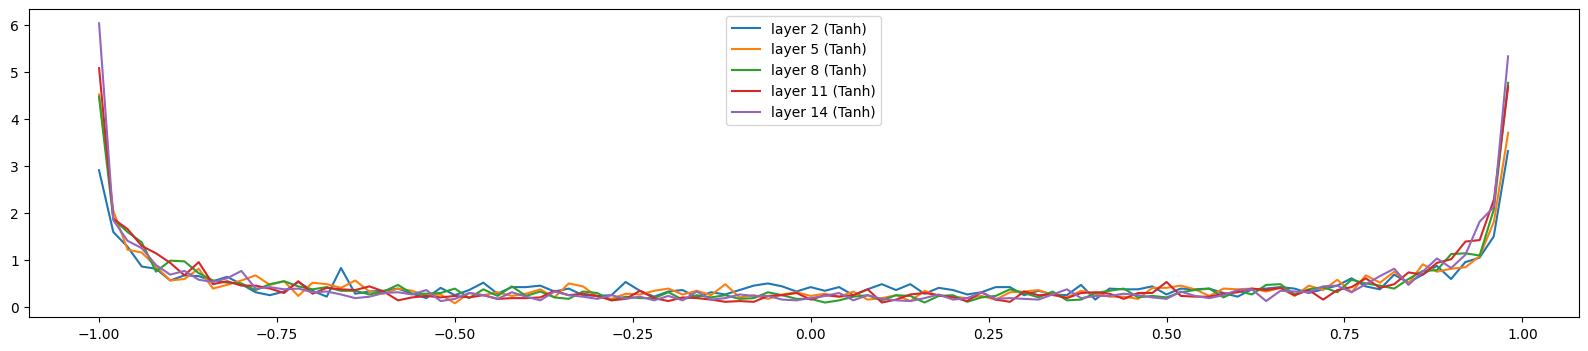

In [13]:
plt.figure(figsize=(20,4))
legends=[]
for i,layer in enumerate(layers[:-1]):
    if isinstance(layer,Tanh):
        t=layer.out
        print('layer %d  (%10s): mean %+.2f,std %.2f ,saturated: %.2f%%' % (i,layer.__class__.__name__,t.mean(),t.std(),(t.abs()>0.97).float().mean()*100))
        hy,hx = torch.histogram(t, density=True)
        print(hx.shape)
        plt.plot(hx[:-1].detach(), hy.detach())
        
        legends.append(f"layer {i} ({layer.__class__.__name__})")

plt.legend(legends);
plt.show()

layer2 (      Tanh): mean +0.000000,std 5e-03
layer5 (      Tanh): mean +0.000000,std 5e-03
layer8 (      Tanh): mean +0.000000,std 4e-03
layer11 (      Tanh): mean +0.000000,std 4e-03
layer14 (      Tanh): mean -0.000000,std 4e-03


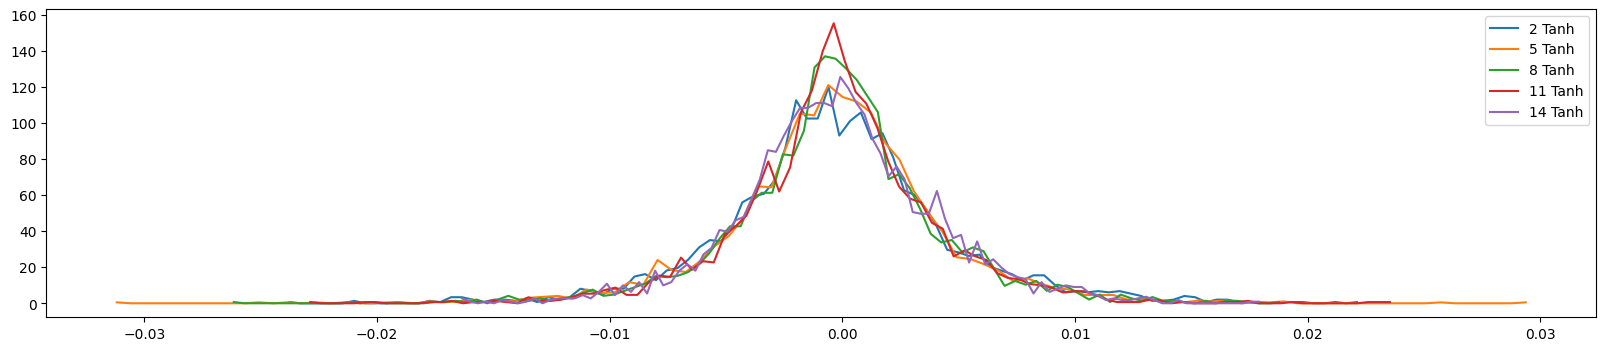

In [14]:
plt.figure(figsize=(20,4))
legends=[]
for i,layer in enumerate(layers[:-1]):
    if isinstance(layer,Tanh):
        t=layer.out.grad
        print("layer%d (%10s): mean %+f,std %.e"%(i,layer.__class__.__name__,t.mean(),t.std()))
        hy,hx=torch.histogram(t,density=True)
        plt.plot(hx[:-1].detach(),hy.detach())
        legends.append(f"{i} {layer.__class__.__name__}")
plt.legend(legends);

weight    (27, 10) |mean  0.000000 | std  1.759543e-02| grad:dataratio 1.391635e-02
weight   (40, 100) |mean  0.000053 | std  8.746836e-03| grad:dataratio 1.843786e-02
weight  (100, 100) |mean  0.000058 | std  5.878303e-03| grad:dataratio 1.829072e-02
weight  (100, 100) |mean  0.000088 | std  5.577142e-03| grad:dataratio 1.766507e-02
weight  (100, 100) |mean  0.000041 | std  5.193791e-03| grad:dataratio 1.731019e-02
weight  (100, 100) |mean  -0.000075 | std  4.803089e-03| grad:dataratio 1.713702e-02
weight   (100, 27) |mean  0.000181 | std  7.462977e-03| grad:dataratio 1.777369e-02


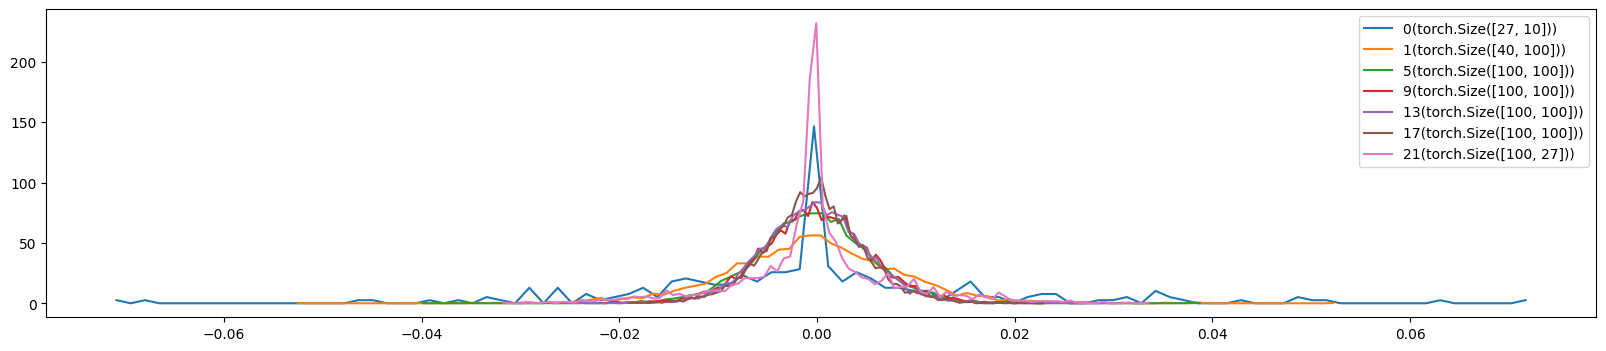

In [15]:
plt.figure(figsize=(20,4))
legends=[]
for i,p in enumerate(parameters):
    t=p.grad
    if p.ndim==2:
        print('weight  %10s |mean  %f | std  %e| grad:dataratio %e'%(tuple(t.shape),t.mean(),t.std(),t.std()/p.std()))
        hy,hx=torch.histogram(t,density=True)
        plt.plot(hx[:-1].detach(),hy.detach())
        legends.append(f'{i}({p.shape})')
plt.legend(legends);

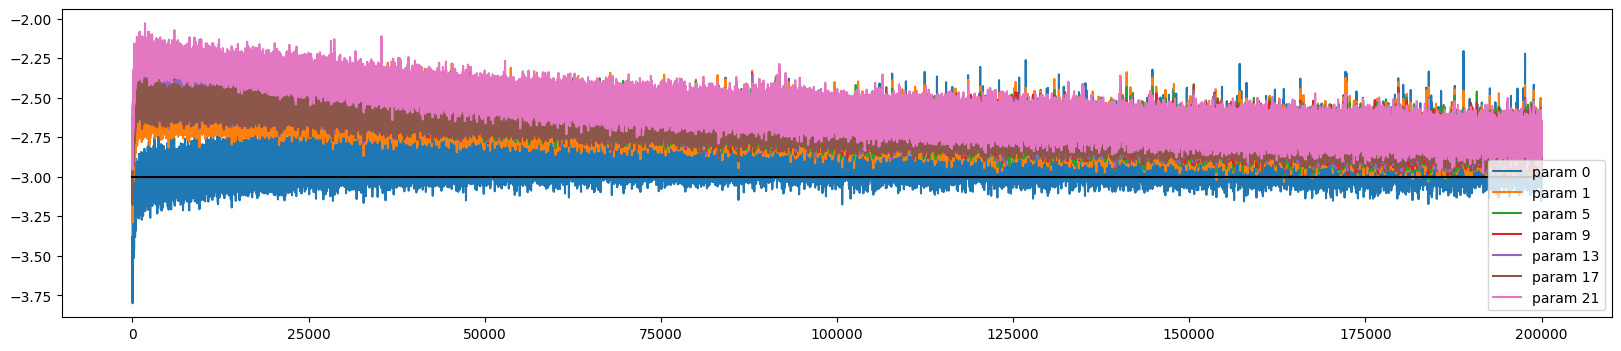

In [112]:
legends=[]
plt.figure(figsize=(20,4))
for i,p in enumerate(parameters):
    if p.ndim==2:
        plt.plot([ud[j][i] for j in range(len(ud))])
        legends.append("param %d" %i)
plt.plot([0,len(ud)],[-3,-3],'k')
plt.legend(legends);
        

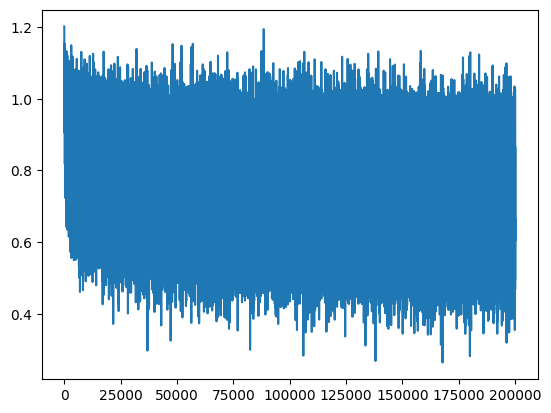

In [113]:
plt.plot(lossi)

In [16]:
@torch.no_grad()
def split_loss(split):
    x,y={
        "train":(Xtr,Ytr),
        "val":(Xdev,Ydev),
        "test":(Xtest,Ytest)
    }[split]
    emd=C[x]
    x=emd.view(emd.shape[0],-1)
    for layer in layers:
        
        x=layer(x)
    loss=F.cross_entropy(x,y)
    print(split,loss.item())
    

In [17]:
split_loss("train")
split_loss("val")

train 1.920819640159607
val 2.0386388301849365


In [18]:
#train 2.0686540603637695
#val 2.1061017513275146

In [23]:
g=torch.Generator().manual_seed(2147483647+10)
blocksize=4
for _ in range(20):
    content=[0]*blocksize
    out=[]
    while True:
        emd=C[torch.tensor(content)]
        x=emd.view(1,-1)
        for layer in layers:
            x=layer(x)
        probs=F.softmax(x,dim=1)
        ix=torch.multinomial(probs,num_samples=1,generator=g).item()
        content=content[1:]+[ix]
        out.append(ix)
        if ix==0:
            break
    print(''.join([itos[i] for i in out]))

C:\Users\seven\AppData\Local\Temp\ipykernel_12756\2468440273.py:24: UserWarning: var(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\ReduceOps.cpp:1861.)
  xvar=x.var(0,keepdim=True,unbiased=True)


RuntimeError: probability tensor contains either `inf`, `nan` or element < 0